# Leyenda: the whole pipeline, from a photo to its caption

This notebook chains the three deliverables on any image given **by folder, by link or by upload**:

```
 image ──► D1  photo or not?  ──(not a photo)──► stop: "not a photo", no caption
            MobileNetV2 fine-tuned 224x224
               │ photo
               ▼
           D2  restoration at the original size
            gate: is there something to repair?  ──(no)──► photo kept unchanged
            U-Net 4 levels (2.76 M parameters), 8-orientation averaging (TTA)
               │
               ▼
           D3  caption
            ConvNeXt-Large (ImageNet, frozen) ──► 81 regions x 1536
            GRU decoder with attention, trained on MS COCO (86,301 images), beam search ──► one sentence
```

Each model is trained in its own notebook (`deliverable1.ipynb`, `deliverable2.ipynb`, `deliverable3.ipynb`); here they
are only **loaded** from `models/` and run one after the other. It is the same workflow as section 13 of
`deliverable3.ipynb`, in a notebook that starts in a few seconds (no training section to run first). For each image the table gives the D1 probability,
what D2 did, the caption **without** and **with** the D2 restoration, and the time.

**For the evaluation dataset:** put the images in a folder and change `INPUT_FOLDER` in the **last cell** only.

In [1]:
import json
import os
import time
import urllib.request
import weakref
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import imageio.v3 as iio
import tensorflow as tf
from PIL import Image

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)   # 2 GB GPU: memory taken when needed
MODELS = Path("models")
needed = ["d1_improved_final.keras", "d1_improved_final.json", "d2_final_unet.keras", "d2_final_config.json",
          "d3_final_captioner.keras", "d3_final_vocab.json", "d3_final_config.json"]
missing = [f for f in needed if not (MODELS / f).exists()]
assert not missing, f"missing in models/: {missing} (run the deliverable notebooks first)"
print("GPU:", [g.name for g in gpus] or "none", "| TensorFlow", tf.__version__, "| all models found")

GPU: ['/physical_device:GPU:0'] | TensorFlow 2.21.0 | all models found


## D1: is it a photograph?

Same input as in `deliverable1.ipynb`: RGB, resized to 224x224 (bilinear), pixels 0-255 (the model does its own
pre-processing). An image is a photo when its probability is at least the threshold chosen in D1 on validation.

**Robust to damaged photos.** D1 was trained on clean images; a strongly noisy photo can look like a drawing to it
(51 % of the validation photos with noise 0.2 were rejected). So an image rejected at first is repaired once by D2 and
shown to D1 again: it is a photo if either probability passes (88.5 % of those photos kept; paintings, diagrams,
sketches and text still rejected in 98-100 % of the cases, see `reports/d1_robustness.csv`).

**Category.** Every image also gets one of the five categories of the TouNum dataset (Photo, Painting, Schematics,
Sketch, Text): a logistic regression on the 1280 numbers of the D1 network just before its photo/not-photo output
(trained on D1's training images, 97.6 % on its test images). A rejected image is therefore not just "not a photo":
it is sorted, and can be copied into one folder per category.

In [2]:
import joblib

d1 = keras.models.load_model(MODELS / "d1_improved_final.keras", compile=False)
D1 = json.loads((MODELS / "d1_improved_final.json").read_text())
d1_dense = [layer for layer in d1.layers if isinstance(layer, keras.layers.Dense)][-1]
d1_embed = keras.Model(d1.inputs, [d1_dense.input, d1.output])      # 1280 features + P(photo), one pass
category_clf = joblib.load(MODELS / "d1_category_classifier.joblib")
CAT = json.loads((MODELS / "d1_category_config.json").read_text())


def d1_classify(img_u8):
    # Returns (P(photo), category).
    x = np.asarray(Image.fromarray(img_u8).resize((D1["img_size"], D1["img_size"]), Image.BILINEAR), np.float32)[None]
    feats, p = d1_embed(x, training=False)
    return float(p.numpy().ravel()[0]), str(category_clf.predict(feats.numpy())[0])


print(f"D1: {D1['model']}, input {D1['img_size']}x{D1['img_size']}, photo if probability >= {D1['threshold']:.2f} | "
      f"categories {CAT['classes']} (test accuracy {CAT['test_accuracy']:.3f})")

D1: P5 = P4 at 224 px, input 224x224, photo if probability >= 0.45 | categories ['Painting', 'Photo', 'Schematics', 'Sketch', 'Text'] (test accuracy 0.976)


## D2: restoration at the original size

The U-Net is fully convolutional, so it runs on the whole photo without shrinking it (large photos are cut into
overlapping tiles). **Gate:** one pass gives a first result; the photo is restored only if the network makes a real
correction (mean change >= `gate_correction`) or makes it sharper (edges after / before >= `gate_sharpening`);
otherwise it is returned unchanged. A restored photo is the average of 8 orientations (test-time augmentation).

In [3]:
d2 = keras.models.load_model(MODELS / "d2_final_unet.keras", compile=False)
D2 = json.loads((MODELS / "d2_final_config.json").read_text())
POOL = 2 ** sum(isinstance(layer, keras.layers.MaxPooling2D) for layer in d2.layers)   # 16: size multiple
TILE, MARGIN = 256, 48   # small tiles: D1, D2, ConvNeXt-Large and the decoder share a 2 GB GPU


def unet_once(img):
    # img (H, W, 3) in [0, 1] -> same size, one pass (tiles for large images).
    def direct(x):
        h, w = x.shape[:2]
        p = np.pad(x, ((0, -h % POOL), (0, -w % POOL), (0, 0)), mode="reflect")
        return d2(p[None], training=False).numpy()[0, :h, :w]
    h, w = img.shape[:2]
    if h * w <= TILE * TILE:
        return direct(img)
    out = np.empty_like(img)
    for y in range(0, h, TILE):
        for x in range(0, w, TILE):
            y0, x0, y1, x1 = max(y - MARGIN, 0), max(x - MARGIN, 0), min(y + TILE + MARGIN, h), min(x + TILE + MARGIN, w)
            piece = direct(img[y0:y1, x0:x1])
            out[y:y + TILE, x:x + TILE] = piece[y - y0:y - y0 + min(TILE, h - y), x - x0:x - x0 + min(TILE, w - x)]
    return out


def edges(img):
    g = img.mean(axis=-1)
    return np.abs(np.diff(g, axis=0)).sum() + np.abs(np.diff(g, axis=1)).sum()


def restore(img01):
    # Returns (restored image, what was done, correction, sharpening).
    first = np.clip(unet_once(img01), 0, 1)
    correction, sharpening = float(np.abs(first - img01).mean()), edges(first) / max(edges(img01), 1e-8)
    if correction < D2["gate_correction"] and sharpening < D2["gate_sharpening"]:
        return img01, "clean: unchanged", correction, sharpening
    outs = []
    for k in range(4):   # test-time augmentation: 4 rotations x (with / without mirror), turned back, averaged
        for mirror in (False, True):
            x = np.rot90(img01, k)
            x = x[:, ::-1] if mirror else x
            y = unet_once(np.ascontiguousarray(x))
            y = y[:, ::-1] if mirror else y
            outs.append(np.rot90(y, -k))
    return np.clip(np.mean(outs, axis=0), 0, 1), "restored", correction, sharpening


print(f"D2: {D2['model']} | gate: correction >= {D2['gate_correction']} or sharpening >= {D2['gate_sharpening']}")

D2: Larger U-Net (13.2), 2.76M parameters, fine-tuned for heavy blur (section 17) | gate: correction >= 0.0275 or sharpening >= 1.3


## D3: the caption

Same pre-processing as in `deliverable3.ipynb`: the image is resized to the encoder size (288x288) and goes through
ConvNeXt-Large (pre-trained on ImageNet, frozen), which gives 9x9 = 81 regions of 1536 numbers. The encoder runs on
the **CPU**: D1, D2, ConvNeXt-Large (196 M parameters) and the decoder do not fit together in a 2 GB GPU; on the CPU it
takes a few seconds per photo and gives the same features (to rounding: 32-bit here, 16-bit when the training features
were computed). The trained decoder then writes
the caption word by word, looking at the regions with its attention, until it writes `<end>`: **beam search** with 3
beams (the 3 most likely partial sentences are kept at each step) and no repeated pair of words, the decoding chosen on
validation in `deliverable3.ipynb`.

In [4]:
D3 = json.loads((MODELS / "d3_final_config.json").read_text())
vocab = json.loads((MODELS / "d3_final_vocab.json").read_text())
word_index = {w: i for i, w in enumerate(vocab)}
captioner = keras.models.load_model(MODELS / "d3_final_captioner.keras", compile=False)
ENC = (D3["encoder_input"], D3["encoder_input"], 3)
with tf.device("/CPU:0"):   # see the text above
    encoder = keras.applications.ConvNeXtLarge(include_top=False, weights="imagenet", input_shape=ENC)
encoder.trainable = False
BANNED = [word_index["<pad>"], word_index["<unk>"], word_index["<start>"]]
L, V = D3["max_len"] - 1, len(vocab)


@tf.function(reduce_retracing=True)
def next_word_scores(f, seq, t):
    # Scores of the next word at position t only (less data copied back from the GPU).
    return captioner([f, seq], training=False)[:, t]


def blocked(words, n):
    # Words that would repeat an n-gram already written.
    if n <= 0 or len(words) < n - 1:
        return []
    prefix = tuple(words[len(words) - n + 1:]) if n > 1 else ()
    return [words[i + n - 1] for i in range(len(words) - n + 1) if tuple(words[i:i + n - 1]) == prefix]


def beam_caption(feats, k, no_repeat):
    # Beam search for ONE image: keeps the k most likely partial sentences, never repeats an n-gram.
    F = np.repeat(feats, k, axis=0)
    seq = np.zeros((k, L), np.int32)
    seq[:, 0] = word_index["<start>"]
    score = np.full(k, -np.inf)
    score[0] = 0.0
    done = np.zeros(k, bool)
    words = np.zeros((k, L), np.int32)
    for t in range(L):
        logits = next_word_scores(F, seq, tf.constant(t)).numpy().astype(np.float64)
        m = logits.max(1, keepdims=True)
        logp = logits - m - np.log(np.exp(logits - m).sum(1, keepdims=True))
        logp[:, BANNED] = -np.inf
        for j in range(k):
            if not done[j]:
                b = blocked(list(words[j, :t]), no_repeat)
                if b:
                    logp[j, b] = -np.inf
        logp[done] = -np.inf
        logp[done, word_index["<pad>"]] = 0.0
        cand = (score[:, None] + logp).ravel()
        top = np.argpartition(-cand, k)[:k] if k > 1 else cand.argmax()[None]
        beam, word = top // V, top % V
        score, seq, words, done = cand[top], seq[beam], words[beam], done[beam]
        words[:, t] = word
        done = done | (word == word_index["<end>"])
        if t + 1 < L:
            seq[:, t + 1] = np.where(done, word_index["<pad>"], word)
        if done.all():
            break
    out = []
    for x in words[score.argmax()]:
        if x in (word_index["<end>"], word_index["<pad>"]):
            break
        out.append(vocab[x])
    return " ".join(out)


def caption(img01):
    x = tf.image.resize(img01[None] * 255.0, [D3["encoder_input"], D3["encoder_input"]], antialias=True)
    with tf.device("/CPU:0"):
        feats = tf.reshape(encoder(x, training=False), (1, D3["regions"], D3["feature_dim"])).numpy()
    return beam_caption(feats, D3["beam"], D3["no_repeat_ngram"])


print(f"D3: {D3['encoder']} -> {D3['regions']} x {D3['feature_dim']} | {D3['training']} | beam {D3['beam']}, "
      f"no repeated {D3['no_repeat_ngram']}-gram | test ({D3['test_photos']:,} photos): BLEU-4 {D3['test_bleu4']}, "
      f"CIDEr-D {D3['test_cider_d']}")

D3: ConvNeXtLarge (ImageNet-22k then 1k, frozen, include_top=False) -> 81 x 1536 | cross-entropy then SCST | beam 3, no repeated 2-gram | test (18,493 photos): BLEU-4 0.301, CIDEr-D 1.124


## Inputs and the pipeline

Three ways to give images: a **folder**, a list of **links** (URLs), or the **upload** button below (in an
interactive session). `run_pipeline` takes a list of `(name, image)` and shows, for each image, the input, the image
after D2 and the captions.

In [5]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def read_rgb(source):
    # Path or bytes -> RGB uint8 array (imageio; grey or RGBA images converted to RGB).
    return np.ascontiguousarray(iio.imread(source, mode="RGB"))


def from_folder(folder):
    return [(p.name, read_rgb(p)) for p in sorted(Path(folder).iterdir()) if p.suffix.lower() in EXTENSIONS]


def from_urls(urls):
    items = []
    for url in urls:
        try:
            data = urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=30).read()
            items.append((url.rsplit("/", 1)[-1][:40] or url, read_rgb(data)))
        except Exception as e:
            print(f"could not read {url}: {type(e).__name__}: {e}")
    return items


def run_pipeline(items, show=12, sort_to=None):
    # items: list of (name, RGB uint8 image). sort_to: folder where each image is copied into <category>/ (optional).
    rows, figs = [], []
    for name, img in items:
        t0 = time.time()
        x = img.astype(np.float32) / 255.0
        p, category = d1_classify(img)
        row = {"image": name, "size": f"{img.shape[1]}x{img.shape[0]}", "P(photo) D1": round(p, 3)}
        restored = done = None
        if p < D1["threshold"]:                       # rejected at first: maybe a damaged photo -> repair once, ask again
            restored, done, corr, sharp = restore(x)
            if done == "restored":
                p2, cat2 = d1_classify((restored * 255).round().astype(np.uint8))
                row["P(photo) after D2"] = round(p2, 3)
                if p2 >= D1["threshold"]:
                    p, category = p2, cat2
        is_photo = p >= D1["threshold"]
        row["category"] = category if not is_photo else "Photo"
        if not is_photo:
            row.update({"D1": "not a photo: stop", "D2": "-", "caption without D2": "-", "caption (final)": "-"})
            figs.append((name, img, None, f"NOT A PHOTO: {category}\n(P(photo) = {row['P(photo) D1']:.2f})"))
        else:
            if restored is None:
                restored, done, corr, sharp = restore(x)
            final = caption(restored)
            row.update({"D1": "photo", "D2": f"{done} (correction {corr:.3f}, sharpening {sharp:.2f})",
                        "caption without D2": caption(x) if done == "restored" else final, "caption (final)": final})
            figs.append((name, img, restored, final))
        if sort_to:
            folder = Path(sort_to) / row["category"]
            folder.mkdir(parents=True, exist_ok=True)
            iio.imwrite(folder / f"{Path(name).stem}.png", img)
        row["seconds"] = round(time.time() - t0, 1)
        rows.append(row)
    table = pd.DataFrame(rows)
    display(table.style.set_properties(**{"text-align": "left"}))
    n = min(show, len(figs))
    if n:
        fig, axes = plt.subplots(n, 2, figsize=(11, 4.6 * n), squeeze=False)
        for r, (name, img, restored, text) in enumerate(figs[:n]):
            axes[r, 0].imshow(img); axes[r, 0].set_title(f"input: {name}", fontsize=10)
            if restored is None:
                axes[r, 1].text(0.5, 0.5, text, ha="center", va="center", fontsize=12, color="firebrick")
            else:
                axes[r, 1].imshow(restored); axes[r, 1].set_title(f"after D2\n\"{text}\"", fontsize=11, color="navy")
            for ax in axes[r]:
                ax.axis("off")
        plt.tight_layout(); plt.show()
    return table

## Demo 1: a folder with every kind of input

Photos never seen by any model (picsum.photos): one clean, two noisy, one with scan-like damage (blur + JPEG + grain),
one blurred; and two images that are **not** photographs (a sketch and a diagram from the D1 dataset), which D1 must
stop before D2 and D3.

Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))


Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))


,image,size,P(photo) D1,category,D1,D2,caption without D2,caption (final),seconds,P(photo) after D2
0,01_clean_photo.png,640x480,0.945000,Photo,photo,"restored (correction 0.008, sharpening 1.34)",a white house sitting on top of a wooden pier,a wooden dock with a house in the background,13.300000,nan
1,02_noisy_photo.png,480x640,0.779000,Photo,photo,"restored (correction 0.074, sharpening 0.10)",a woman sitting at a table with a laptop,a woman sitting at a table with a laptop,8.400000,nan
2,03_very_noisy_photo.png,480x640,0.053000,Photo,photo,"restored (correction 0.129, sharpening 0.17)",a black and white photo of a body of water,a black and white photo of a boat on the water,8.600000,0.963000
3,04_scan_damaged_photo.png,1024x768,0.755000,Photo,photo,"restored (correction 0.073, sharpening 0.25)",a black and white photo of a boat on the water,a black and white photo of a boat on the water,11.500000,nan
4,05_blurred_photo.png,480x640,0.100000,Painting,not a photo: stop,-,-,-,0.500000,nan
5,06_sketch_not_a_photo.jpg,411x583,0.026000,Sketch,not a photo: stop,-,-,-,1.000000,nan
6,07_diagram_not_a_photo.jpg,787x695,0.023000,Schematics,not a photo: stop,-,-,-,1.800000,nan


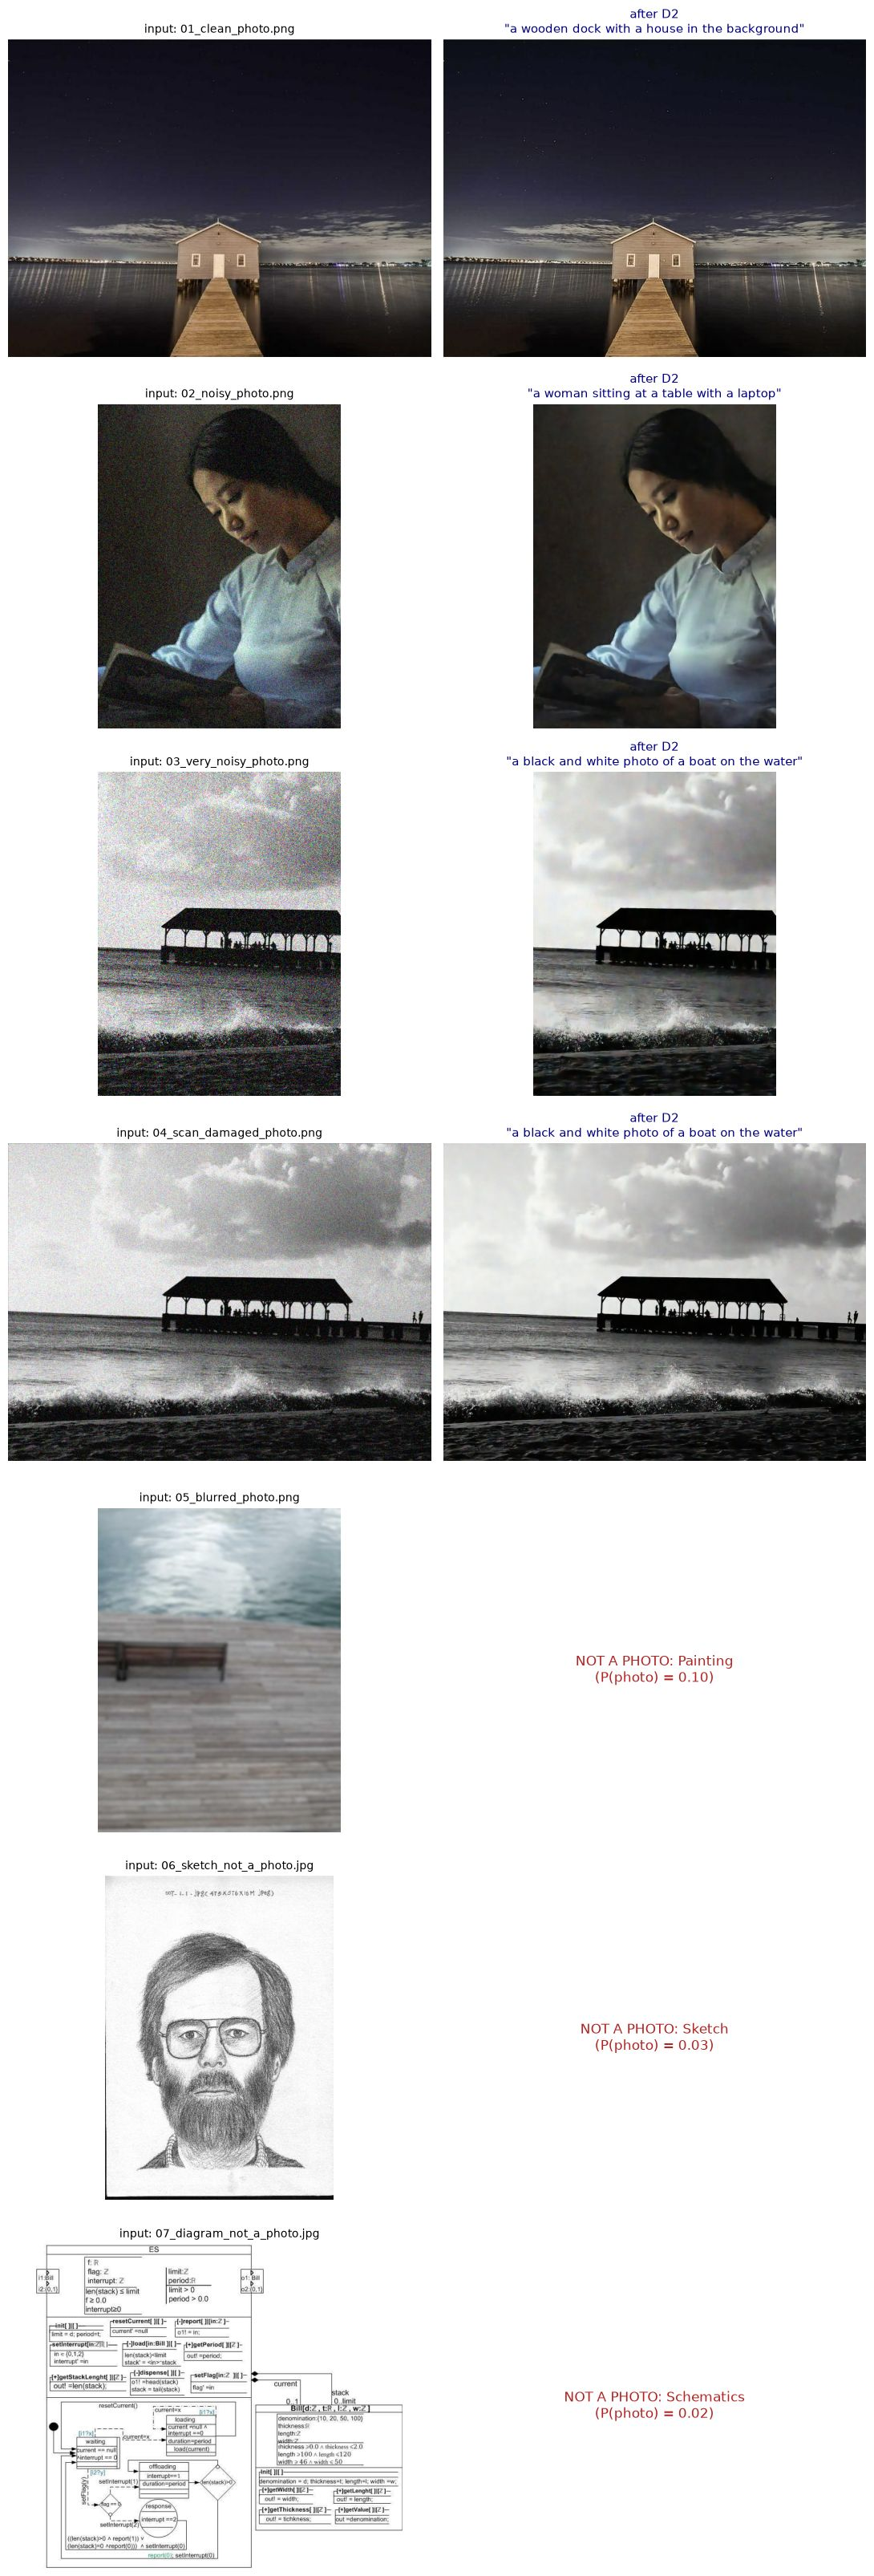

In [6]:
demo = run_pipeline(from_folder("demo_images"))

## Demo 2: images given by link

Any public image address works; here two random photographs from picsum.photos (needs internet).

Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))


,image,size,P(photo) D1,category,D1,D2,caption without D2,caption (final),seconds
0,480,640x480,0.436000,Painting,not a photo: stop,-,-,-,0.500000
1,480,640x480,0.966000,Photo,photo,"restored (correction 0.009, sharpening 1.31)",a man laying on a surfboard in the water,a man laying on a surfboard in the water,8.300000


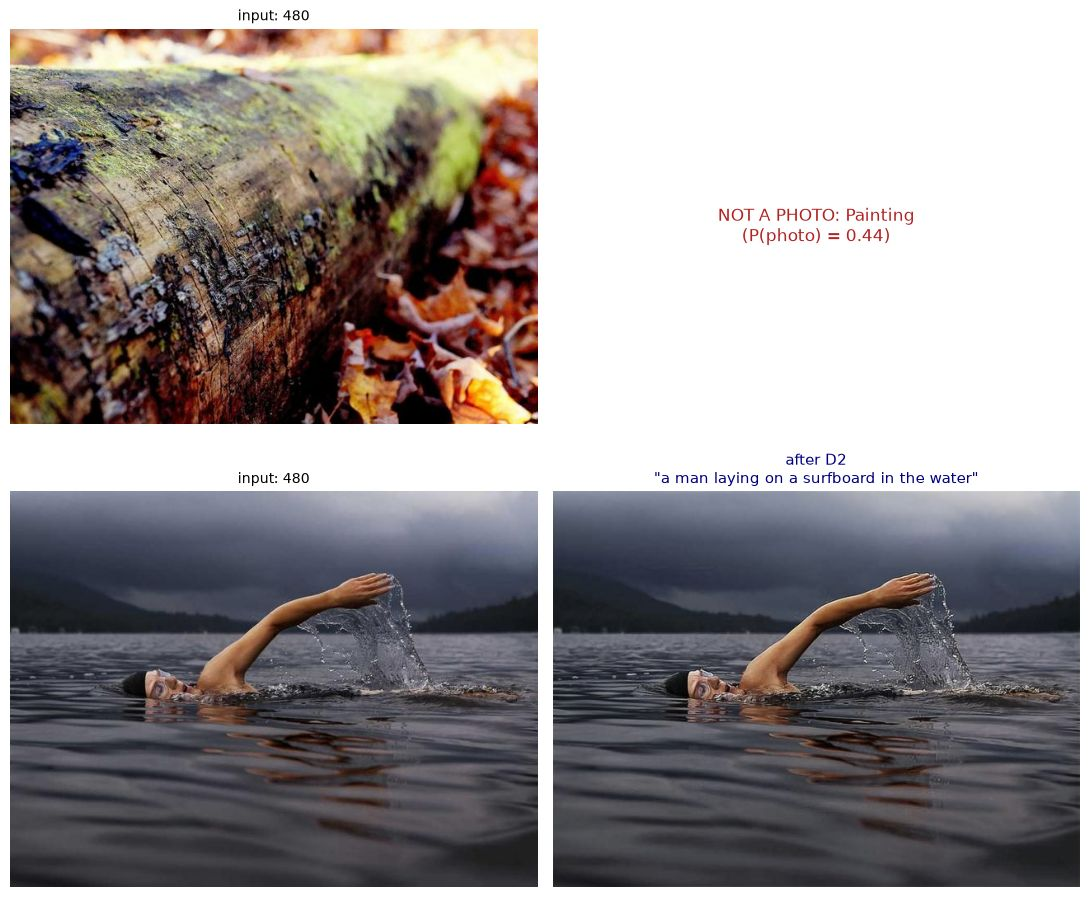

In [7]:
links = ["https://picsum.photos/seed/tounum1/640/480", "https://picsum.photos/seed/tounum2/640/480"]
by_link = run_pipeline(from_urls(links))

## Your own photos (manual input)

Two ways that always work, in VS Code or Jupyter:

1. **Drop your photos in the folder `my_photos/`** (next to this notebook), then run the cell below.
2. **Or paste file paths or web links** in `MY_IMAGES` (one string per image), then run the cell.

In [8]:
MY_FOLDER = "my_photos"   # drop your photos here
MY_IMAGES = [             # or paste paths / links here, e.g. "/home/me/Pictures/holiday.jpg" or "https://.../photo.jpg"
]
Path(MY_FOLDER).mkdir(exist_ok=True)
mine = from_folder(MY_FOLDER) + [(Path(s).name, read_rgb(s)) for s in MY_IMAGES if not s.startswith("http")] \
       + from_urls([s for s in MY_IMAGES if s.startswith("http")])
if mine:
    my_results = run_pipeline(mine)
else:
    print(f"No image yet: put photos in '{MY_FOLDER}/' or paste paths/links in MY_IMAGES, then run this cell again.")

No image yet: put photos in 'my_photos/' or paste paths/links in MY_IMAGES, then run this cell again.


## Demo 3: upload your own images

In an interactive session, click the button, choose one or more images, then run the next cell.

In [9]:
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Upload images")
display(uploader)

FileUpload(value=(), accept='image/*', description='Upload images', multiple=True)

In [10]:
uploaded = [(f["name"], read_rgb(bytes(f["content"]))) for f in uploader.value]
if uploaded:
    run_pipeline(uploaded)
else:
    print("No image uploaded yet: use the button above, then run this cell again.")

No image uploaded yet: use the button above, then run this cell again.


## Evaluation dataset (last cell)

**Change only `INPUT_FOLDER`** to the folder of the dataset given for the demonstration, then run the cell. The full
table is also saved to `reports/pipeline_results.csv`.

Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
Expected: ['input_layer_11']
Received: inputs=Tensor(shape=(1, 224, 224, 3))


,image,size,P(photo) D1,category,D1,D2,caption without D2,caption (final),seconds,P(photo) after D2
0,01_clean_photo.png,640x480,0.945000,Photo,photo,"restored (correction 0.008, sharpening 1.34)",a white house sitting on top of a wooden pier,a wooden dock with a house in the background,8.800000,nan
1,02_noisy_photo.png,480x640,0.779000,Photo,photo,"restored (correction 0.074, sharpening 0.10)",a woman sitting at a table with a laptop,a woman sitting at a table with a laptop,8.500000,nan
2,03_very_noisy_photo.png,480x640,0.053000,Photo,photo,"restored (correction 0.129, sharpening 0.17)",a black and white photo of a body of water,a black and white photo of a boat on the water,9.700000,0.963000
3,04_scan_damaged_photo.png,1024x768,0.755000,Photo,photo,"restored (correction 0.073, sharpening 0.25)",a black and white photo of a boat on the water,a black and white photo of a boat on the water,12.000000,nan
4,05_blurred_photo.png,480x640,0.100000,Painting,not a photo: stop,-,-,-,0.600000,nan
5,06_sketch_not_a_photo.jpg,411x583,0.026000,Sketch,not a photo: stop,-,-,-,0.500000,nan
6,07_diagram_not_a_photo.jpg,787x695,0.023000,Schematics,not a photo: stop,-,-,-,0.800000,nan


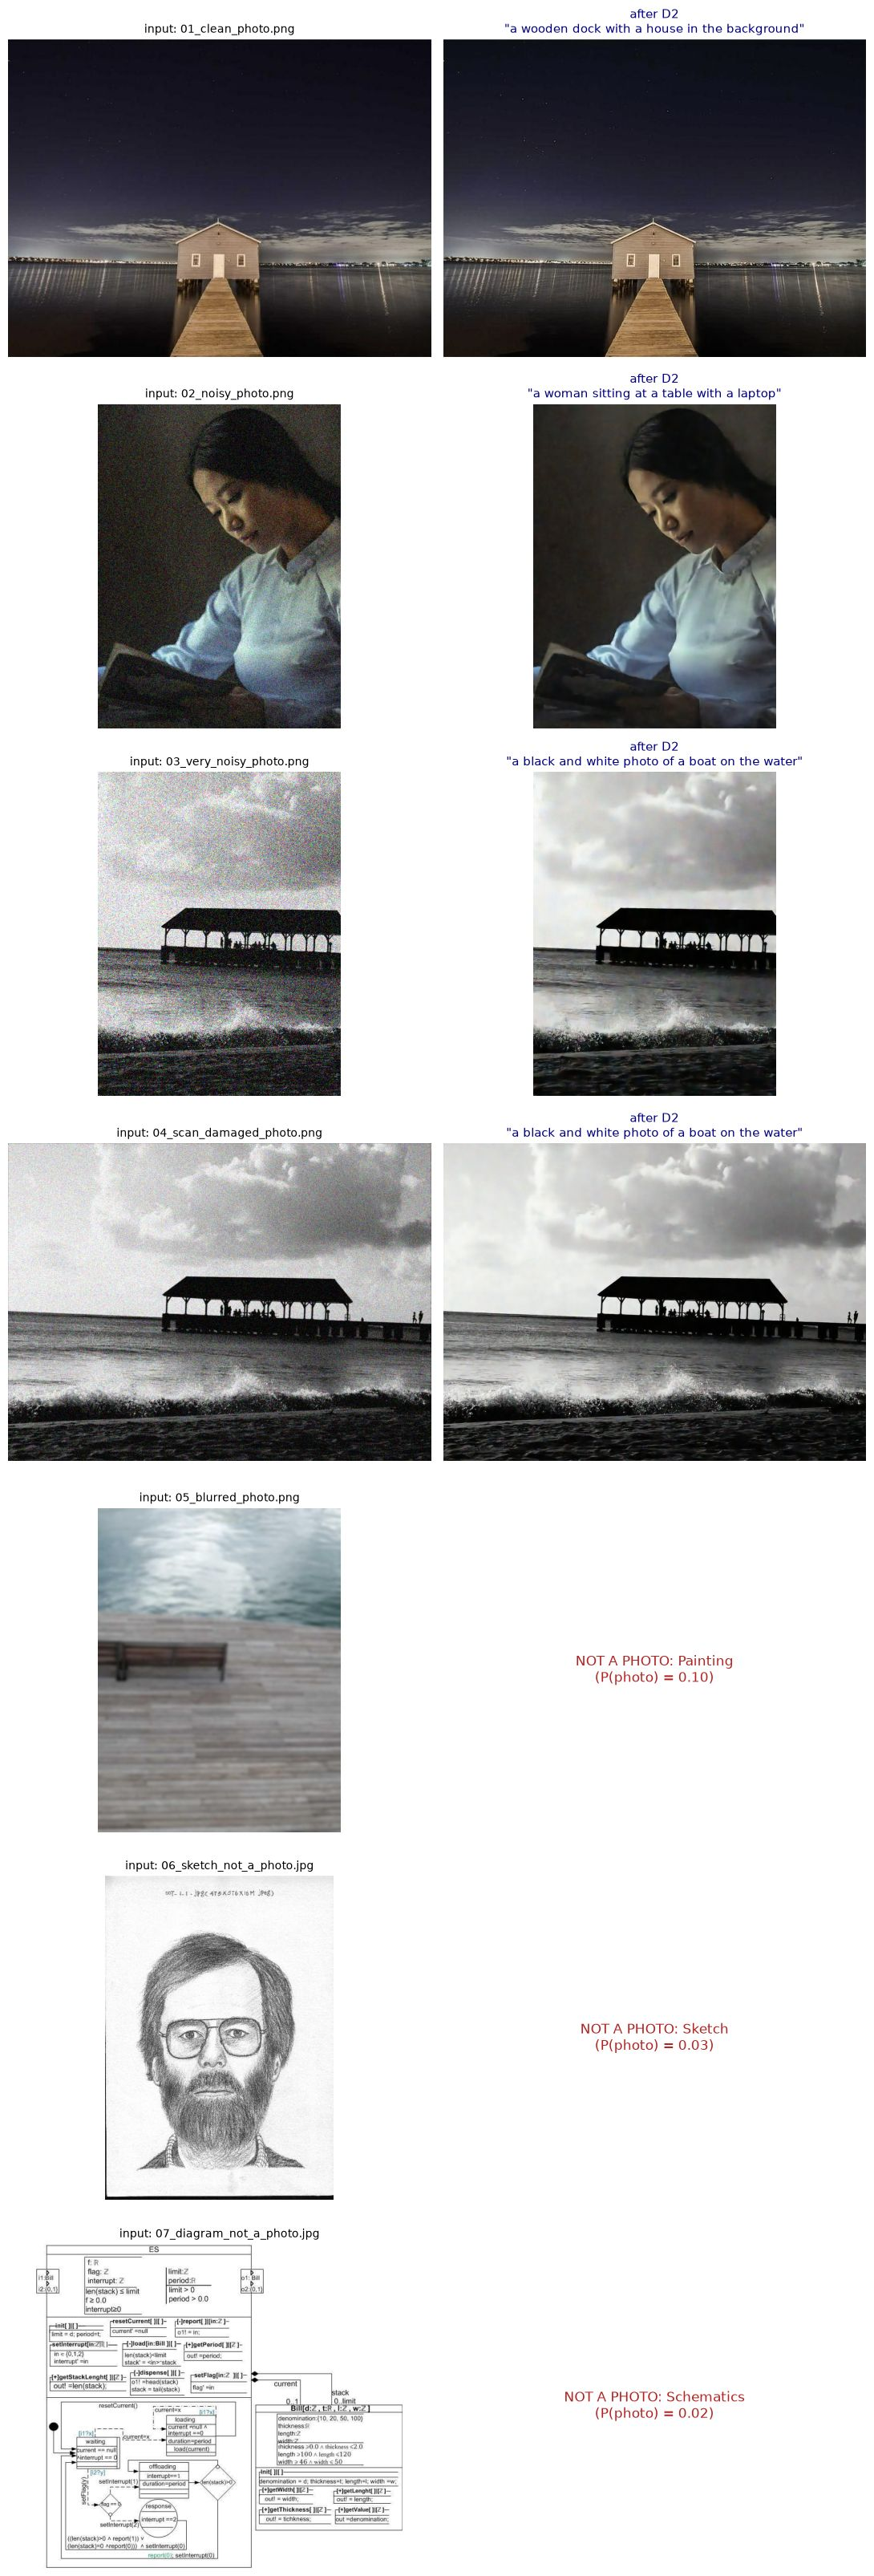

7 images | photos: 4 (restored by D2: 4) | total 41 s
by category: {'Photo': 4, 'Painting': 1, 'Sketch': 1, 'Schematics': 1} -> copied into data/sorted_output/<category>/


In [11]:
INPUT_FOLDER = "demo_images"   # <- the evaluation dataset folder
SORTED_FOLDER = "data/sorted_output"    # each image is copied into <category>/ here
results = run_pipeline(from_folder(INPUT_FOLDER), sort_to=SORTED_FOLDER)
results.to_csv("reports/pipeline_results.csv", index=False)
print(f"{len(results)} images | photos: {(results['D1'] == 'photo').sum()} (restored by D2: "
      f"{results['D2'].str.startswith('restored').sum()}) | total {results['seconds'].sum():.0f} s")
print("by category:", results["category"].value_counts().to_dict(), f"-> copied into {SORTED_FOLDER}/<category>/")